In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/movie-recommendation-hackathon-2026/sample_submission.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/imdb_data.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_scores.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/links.csv


In [3]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, root_mean_squared_error
from sklearn.model_selection import train_test_split, ParameterGrid
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import kneighbors_graph

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv')

train_df.head()

,userId,movieId,rating,timestamp
0,5163,57669,4.0,1518349992
1,106343,5,4.5,1206238739
2,146790,5459,5.0,1076215539
3,106362,32296,2.0,1423042565
4,9041,366,3.0,833375837


In [5]:
movies_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv')

movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## KMeans Evaluation

In [6]:
train_data, validation_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42
)

In [7]:
# Encode user and movie Ids
user_codes, user_ids = pd.factorize(
    train_data['userId'],
    sort=True
)

movie_codes, movie_ids = pd.factorize(
    train_data['movieId'],
    sort=True
)

# Create 1D-to-index mappings
user_id_to_idx = pd.Series(
    np.arange(len(user_ids)),
    index=user_ids
)

movie_id_to_idx = pd.Series(
    np.arange(len(movie_ids)),
    index=movie_ids
)

# Construct the user-item matrix
user_item_matrix = csr_matrix(
    (
        train_data['rating'].to_numpy(dtype=np.float32),
        (user_codes, movie_codes)
    ),
    shape=(len(user_ids), len(movie_ids))
)

In [17]:
inertia_values = []

for k in range(2, 20):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(user_item_matrix)

    inertia_values.append(kmeans.inertia_)

In [22]:
k_values = range(2, 20)

results_df = pd.DataFrame({
    'n_clusters': list(k_values),
    'inertia': inertia_values
})

results_df.to_csv('kmeans_elbow_results.csv', index=False)

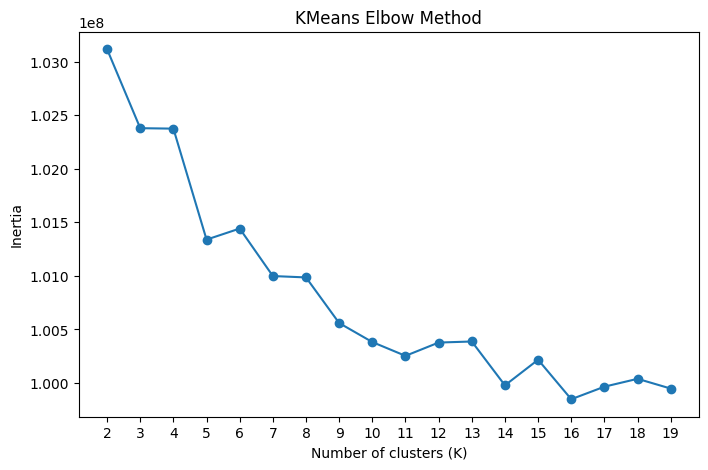

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(2, 20),
    inertia_values,
    marker='o'
)


plt.xticks(range(2, 20))
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('KMeans Elbow Method')

plt.show()

In [23]:
best_k = 16

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(user_item_matrix)

user_clusters = pd.DataFrame({
    'userId': user_ids,
    'cluster': cluster_labels
})

print(user_clusters['cluster'].value_counts().sort_index())

cluster
0     13899
1      7349
2     10405
3     22181
4       877
5      8438
6     10814
7         1
8         1
9      5811
10     3967
11    12787
12     3795
13     2677
14    59535
15        1
Name: count, dtype: int64


In [24]:
user_clusters.head()

,userId,cluster
0,1,14
1,2,3
2,3,13
3,4,1
4,5,0


In [35]:
def kmeans_recommender_fn(train_data, movies_df, user_clusters, user_id, n=10):
    # Check whether the user exists
    if user_id not in user_clusters['userId'].values:
        raise ValueError(f"User {user_id} was not found.")

    # Identify the cluster assigned to the target user
    user_cluster = user_clusters.loc[
        user_clusters['userId'] == user_id, 'cluster'
    ].iloc[0]

    # Get the IDs of users belonging to the same cluster
    cluster_user_ids = user_clusters.loc[
        user_clusters['cluster'] == user_cluster, 'userId'
    ]

    # Exclude the target user when calculating recommendations
    cluster_ratings = train_data[
        (train_data['userId'].isin(cluster_user_ids)) &
        (train_data['userId'] != user_id)
    ]

    # Calculate the average rating for each movie
    movie_ratings = (
        cluster_ratings
        .groupby('movieId')['rating']
        .mean()
        .reset_index(name='predicted_rating')
    )

    # Identify movies the target user has already rated
    rated_movies = train_data.loc[
        train_data['userId'] == user_id, 'movieId'
    ].unique()

    # Exclude movies the target user has already rated
    recommendations = movie_ratings[
        ~movie_ratings['movieId'].isin(rated_movies)
    ]

    # Sort recommendations by predicted rating
    recommendations = recommendations.sort_values(
        by='predicted_rating',
        ascending=False
    )

    # Select the top N recommendations
    recommendations = recommendations.head(n)

    # Add movie titles
    recommendations = recommendations.merge(
        movies_df[['movieId', 'title']],
        on='movieId',
        how='left'
    )

    return recommendations

In [37]:
recommendations = kmeans_recommender_fn(
    train_data=train_data,
    movies_df=movies_df,
    user_clusters=user_clusters,
    user_id=314
)

print(recommendations)

   movieId  predicted_rating  \
0   115149               5.0   
1   115210               5.0   
2   106072               5.0   
3      654               5.0   
4      636               5.0   
5   164909               5.0   
6   162606               5.0   
7   112552               5.0   
8     2377               5.0   
9     2364               5.0   

                                               title  
0                                   John Wick (2014)  
1                                        Fury (2014)  
2                        Thor: The Dark World (2013)  
3  And Nobody Weeps for Me (Und keiner weint mir ...  
4                                       Frisk (1995)  
5                                  La La Land (2016)  
6                              The Accountant (2016)  
7                                    Whiplash (2014)  
8                                   Lifeforce (1985)  
9  Godzilla 1985: The Legend Is Reborn (Gojira) (...  


In [40]:
validation_data.head()

,userId,movieId,rating,timestamp
5954604,122380,31445,2.5,1159967140
1460784,22380,56775,4.0,1343936580
6631832,104339,356,2.5,1111529397
5396407,64877,6874,4.0,1513800297
8150654,63164,2762,5.0,1005315064


In [41]:
user_clusters.head()

,userId,cluster
0,1,14
1,2,3
2,3,13
3,4,1
4,5,0


In [47]:
cluster_ratings = train_data.merge(
    user_clusters,
    on='userId',
    how='inner'
)

cluster_movie_stats = (
    cluster_ratings
    .groupby(['cluster', 'movieId'])['rating']
    .agg(['sum', 'count'])
    .reset_index()
)

validation_predictions = validation_data.merge(
    user_clusters,
    on='userId',
    how='left'
)

validation_predictions = validation_predictions.merge(
    cluster_movie_stats,
    on=['cluster', 'movieId'],
    how='left'
)

own_ratings = train_data[['userId', 'movieId', 'rating']].rename(
    columns={'rating': 'own_rating'}
)

validation_predictions = validation_predictions.merge(
    own_ratings,
    on=['userId', 'movieId'],
    how='left'
)

validation_predictions['sum'] -= validation_predictions['own_rating'].fillna(0)

validation_predictions['count'] -= (
    validation_predictions['own_rating'].notna().astype(int)
)

validation_predictions['predicted_rating'] = (
    validation_predictions['sum'] /
    validation_predictions['count'].replace(0, np.nan)
)

valid_predictions = validation_predictions.dropna(
    subset=['predicted_rating']
)

rmse = root_mean_squared_error(
    valid_predictions['rating'],
    valid_predictions['predicted_rating']
)

rmse

0.9604334766857959

In [50]:
coverage = len(valid_predictions) / len(validation_data)

print("Prediction coverage: ", round(coverage * 100, 2), "%")

Prediction coverage:  99.18 %


## Hyperparameter Tuning for KMeans

In [ ]:
params_grid = {
    'init': ['k-means++', 'random'],
    'n_init': [10, 20, 30],
    'max_iter': [100, 200, 300]
}

grid_results = []

for params in ParameterGrid(params_grid):
    kmeans = KMeans(
        n_clusters=best_k,
        random_state=42,
        **params
    )

    labels = kmeans.fit_predict(user_item_matrix)

    score = silhouette_score(
        user_item_matrix,
        labels,
        sample_size=10000,
        random_state=42
    )

    grid_results.append({
        'n_clusters': best_k,
        **params,
        'inertia': kmeans.inertia_,
        'silhouette_score': score
    })

gird_results_df = pd.DataFrame(grid_results)

grid_results_df = grid_results_df.sort_values(
    by='silhouette_score',
    ascending=False
)

grid_results_df.to_csv(
    'kmeans_gridsearch_results.csv',
    index=False
)

## Agglomerative Clustering Algorithm

In [54]:
print("Matrix shape: ", user_item_matrix.shape)

print("Number of users: ", user_item_matrix.shape[0])
print("Number of movies: ", user_item_matrix.shape[1])

print(
    "Estimated dense memory: ",
    user_item_matrix.shape[0] * user_item_matrix.shape[1] * 4 / (1024 ** 3),
    "Gb"
)

Matrix shape:  (162538, 45438)
Number of users:  162538
Number of movies:  45438
Estimated dense memory:  27.51276509463787 Gb


### Using a subset of the data

In [58]:
sample_user_ids = np.random.default_rng(42).choice(
    user_ids,
    size=5000,
    replace=False
)

sampled_train_data = train_data[
    train_data['userId'].isin(sample_user_ids)
].copy()

print("Number of users: ", sampled_train_data['userId'].nunique())
print("Number of ratings: ", len(sampled_train_data))

Number of users:  5000
Number of ratings:  243722


In [60]:
sample_user_codes, sample_user_ids = pd.factorize(
    sampled_train_data['userId'],
    sort=True
)

sample_movie_codes, sample_movie_ids = pd.factorize(
    sampled_train_data['movieId'],
    sort=True
)

sample_user_item_matrix = csr_matrix(
    (
        sampled_train_data['rating'].to_numpy(dtype=np.float32),
        (sample_user_codes, sample_movie_codes)
    ),
    shape=(len(sample_user_ids), len(sample_movie_ids))
)

print("Sample matrix shape: ", sample_user_item_matrix.shape)

dense_memory_gb = (
    sample_user_item_matrix.shape[0] *
    sample_user_item_matrix.shape[1] *
    4 / (1024 ** 3)
)

print("Estimated dense memory: ", dense_memory_gb, "GB")

Sample matrix shape:  (5000, 13351)
Estimated dense memory:  0.24868175387382507 GB


In [63]:
sample_user_item_dense = sample_user_item_matrix.toarray()

agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

cluster_labels = agg_model.fit_predict(sample_user_item_dense)

agg_user_clusters = pd.DataFrame({
    'userId': sample_user_ids,
    'cluster': cluster_labels
})

agg_user_clusters['cluster'].value_counts().sort_index()

cluster
0       2
1    3517
2     401
3     970
4     110
Name: count, dtype: int64

### Exploring Dimensionality reduction for the Agglomerative Clustering Algorithm

In [71]:
svd = TruncatedSVD(
    n_components=6200,
    n_iter=5,
    random_state=42
)

svd.fit(user_item_matrix)

cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

cumulative_variance

array([0.03266506, 0.04635139, 0.05390293, ..., 0.9733261 , 0.9733355 ,
       0.9733449 ], dtype=float32)

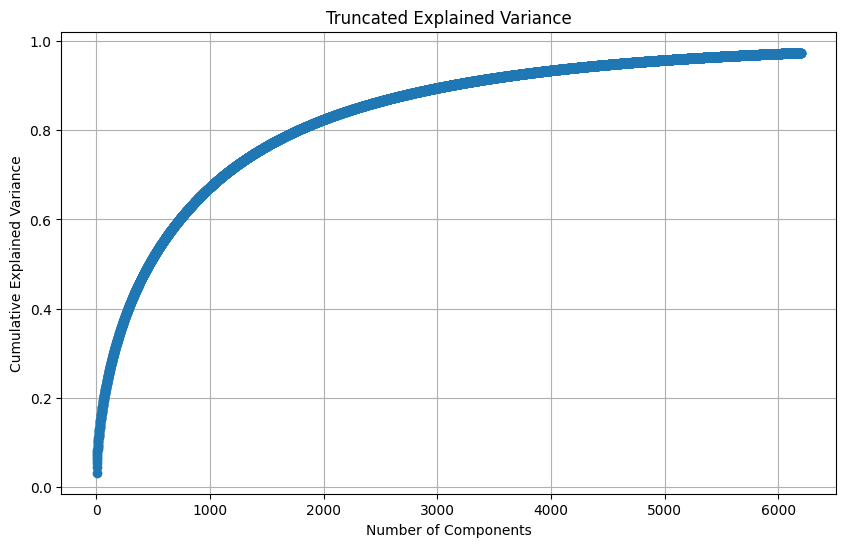

In [72]:
plt.figure(figsize=(10,6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Truncated Explained Variance')
plt.grid(True)

plt.show()

In [73]:
best_n_components = 6200

svd = TruncatedSVD(
    n_components=best_n_components,
    n_iter=5,
    random_state=42
)

user_item_reduced = svd.fit_transform(user_item_matrix)

In [75]:
connectivity = kneighbors_graph(
    user_item_reduced,
    n_neighbors=10,
    mode='connectivity',
    include_self=False,
    n_jobs=-1
)

### import the model files already calculated and loaded

In [8]:
import joblib

svd = joblib.load('/kaggle/working/svd_model.joblib')
user_item_reduced = joblib.load('/kaggle/working/user_item_reduced.joblib')
connectivity = joblib.load('/kaggle/working/connectivity_graph.joblib')

In [ ]:
final_agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward',
    connectivity=connectivity
)

cluster_labels = final_agg_model.fit_predict(user_item_reduced)

In [ ]:
agg_user_clusters = pd.DataFrame({
    'userId': user_ids,
    'cluster': cluster_labels
})

agg_user_clusters['cluster'].value_counts().sort_index()

In [77]:
import joblib

# Save the fitted SVD model
joblib.dump(svd, 'svd_model.joblib', compress=0)

# Save the reduced user-item matrix
joblib.dump(user_item_reduced, 'user_item_reduced.joblib', compress=0)

# Save the connectivity graph
joblib.dump(connectivity, 'connectivity_graph.joblib', compress=0)

['connectivity_graph.joblib']